# Data Analysis Activity Sheet 01


**Name:** Hitesh Kumar  |  **ERP ID:** 35079



In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

---
# Dataset 1: Pakistani E-Commerce Data

**Load the dataset**

In [50]:
df = pd.read_csv('pakistani_ecommerce_dataset.csv')
df.head()

,user_id,gender,age_group,city,product_category,payment_method,order_value,order_status
0,U001,Male,25-34,Islamabad,Home Decor,JazzCash,1899.62,Pending
1,U002,Female,25-34,Lahore,Electronics,EasyPaisa,1592.21,Cancelled
2,U003,Female,25-34,Lahore,Books,Debit Card,3851.78,Cancelled
3,U004,Female,18-24,Lahore,Home Decor,Cash on Delivery,1774.12,Pending
4,U005,Female,35-44,Lahore,Home Decor,EasyPaisa,3611.28,Cancelled


In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           100 non-null    object 
 1   gender            100 non-null    object 
 2   age_group         100 non-null    object 
 3   city              100 non-null    object 
 4   product_category  100 non-null    object 
 5   payment_method    100 non-null    object 
 6   order_value       100 non-null    float64
 7   order_status      100 non-null    object 
dtypes: float64(1), object(7)
memory usage: 6.4+ KB


### Q1: Which is the most popular product category?
Group by category, count the orders, sort in descending order. The top row is the most popular.

In [52]:
# Group by category and count orders
cat_orders = df.groupby('product_category')['user_id'].count()

# Sort descending
cat_orders = cat_orders.sort_values(ascending=False)
cat_orders

,user_id
product_category,
Home Decor,30
Clothing,22
Beauty,19
Electronics,18
Books,11


In [53]:
# Top row = most popular category
cat_orders.head(1)

,user_id
product_category,
Home Decor,30


**Answer:** Home Decor is the most popular category with 30 orders.

### Q2: What is the average order value?

In [54]:
df['order_value'].mean()

np.float64(2832.1480999999994)

**Answer:** The average order value is about Rs. 2,832.15.

### Q3: Which city has the highest number of orders?

In [55]:
# Group by city and count orders, sorted descending
city_orders = df.groupby('city')['user_id'].count().sort_values(ascending=False)
city_orders

,user_id
city,
Karachi,24
Islamabad,21
Rawalpindi,20
Lahore,18
Faisalabad,17


In [56]:
city_orders.head(1)

,user_id
city,
Karachi,24


**Answer:** Karachi has the highest number of orders (24).

### Q4: What is the most used payment method?

In [57]:
# Group by payment method and count orders, sorted descending
pay_orders = df.groupby('payment_method')['user_id'].count().sort_values(ascending=False)
pay_orders

,user_id
payment_method,
Cash on Delivery,29
JazzCash,27
EasyPaisa,23
Debit Card,21


In [58]:
pay_orders.head(1)

,user_id
payment_method,
Cash on Delivery,29


**Answer:** Cash on Delivery is the most used payment method (29 orders).

### Q5: Bar chart showing average order value by city

In [59]:
# Average order value for each city
df.groupby('city')['order_value'].mean()

,order_value
city,
Faisalabad,2937.084118
Islamabad,3011.951429
Karachi,2956.497917
Lahore,2785.330000
Rawalpindi,2447.075500


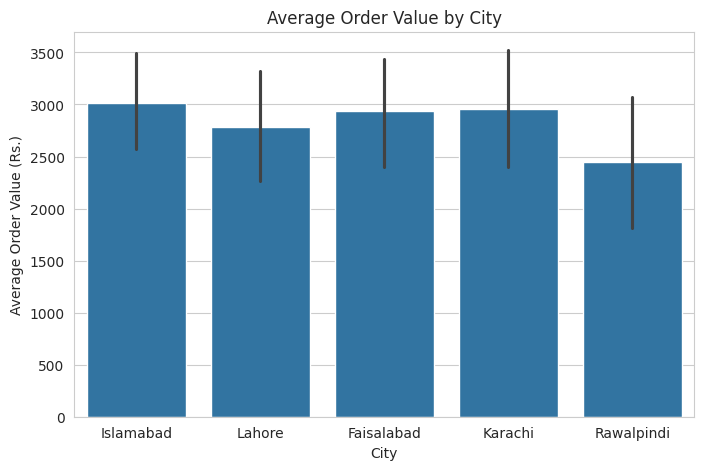

In [60]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='city', y='order_value', estimator='mean')
plt.xlabel('City')
plt.ylabel('Average Order Value (Rs.)')
plt.title('Average Order Value by City')
plt.show()

**Answer:** Islamabad has the highest average order value and Rawalpindi has the lowest.

---
# Dataset 2: Student Lifestyle & Study Habits

**Load the dataset**

In [61]:
df2 = pd.read_csv('student_lifestyle_dataset.csv')
df2.head()

,student_id,gender,study_hours,sleep_hours,screen_time,internet_usage,daily_transport_cost
0,S001,Female,7.0,7.1,2.7,9.3,102.0
1,S002,Female,4.9,6.9,2.9,1.0,284.0
2,S003,Female,5.9,8.9,5.3,5.2,123.0
3,S004,Female,3.2,4.2,1.8,5.2,73.0
4,S005,Male,1.8,5.0,2.5,6.1,202.0


In [62]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            100 non-null    object 
 1   gender                100 non-null    object 
 2   study_hours           100 non-null    float64
 3   sleep_hours           100 non-null    float64
 4   screen_time           100 non-null    float64
 5   internet_usage        100 non-null    float64
 6   daily_transport_cost  100 non-null    float64
dtypes: float64(5), object(2)
memory usage: 5.6+ KB


### Q1: What is the average number of study hours?

In [63]:
df2['study_hours'].mean()

np.float64(4.4030000000000005)

**Answer:** Students study 4.40 hours on average.

### Q2: Who sleeps more on average, males or females?

In [64]:
df2.groupby('gender')['sleep_hours'].mean()

,sleep_hours
gender,
Female,6.796154
Male,6.389583


**Answer:** Females sleep more on average (6.80 hours) than males (6.39 hours).

### Q3: Is there a relationship between screen time and sleep hours?

In [65]:
# Correlation between the two columns
df2[['screen_time', 'sleep_hours']].corr()

,screen_time,sleep_hours
screen_time,1.000000,0.052386
sleep_hours,0.052386,1.000000


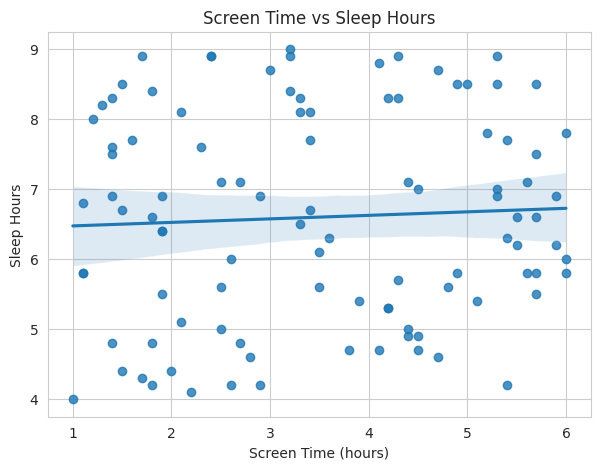

In [66]:
# Scatter plot with regression line
plt.figure(figsize=(7, 5))
sns.regplot(data=df2, x='screen_time', y='sleep_hours')
plt.xlabel('Screen Time (hours)')
plt.ylabel('Sleep Hours')
plt.title('Screen Time vs Sleep Hours')
plt.show()

**Answer:** The correlation is about 0.05, which is very close to 0. So there is no meaningful relationship between screen time and sleep hours.

### Q4: Histogram of daily transport cost

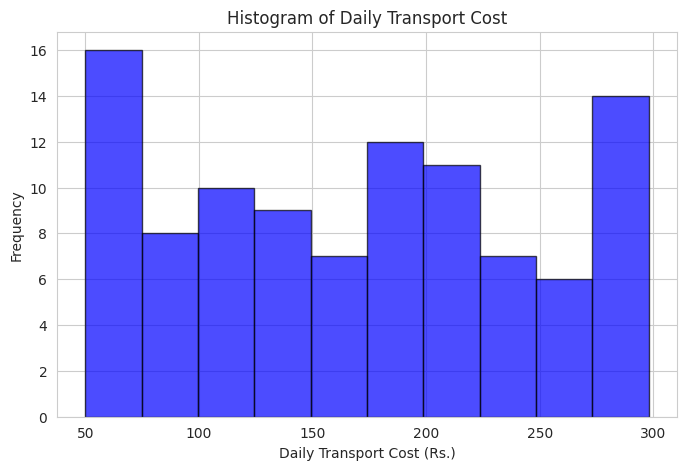

In [67]:
plt.figure(figsize=(8, 5))
plt.hist(df2['daily_transport_cost'], bins=10, color='blue', edgecolor='black', alpha=0.7)
plt.xlabel('Daily Transport Cost (Rs.)')
plt.ylabel('Frequency')
plt.title('Histogram of Daily Transport Cost')
plt.show()

### Q5: Compare average internet usage by gender

In [68]:
df2.groupby('gender')['internet_usage'].mean()

,internet_usage
gender,
Female,5.321154
Male,6.002083


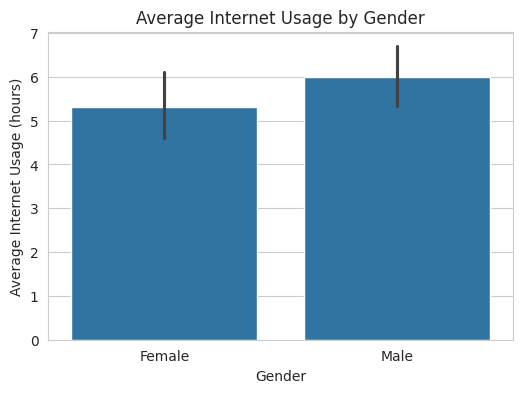

In [69]:
plt.figure(figsize=(6, 4))
sns.barplot(data=df2, x='gender', y='internet_usage', estimator='mean')
plt.xlabel('Gender')
plt.ylabel('Average Internet Usage (hours)')
plt.title('Average Internet Usage by Gender')
plt.show()

**Answer:** Males use the internet more on average (6.00 hours) than females (5.32 hours).